# DATA PROCESSING PIPELINE

```
┌─────────────────────────────────────────────────────────────────────────┐
│ STAGE 1: Data Collection                                                │
│ • Phishing URLs: PhishTank                                              │
│ • Legitimate Domains: Tranco List                                       │
│ • Training Data Collection: 19 September 2026                           │
│ • Testing Data Collection: 28 October 2026                              │
└─────────────────────────────────┬───────────────────────────────────────┘
                                  │
                 ┌────────────────┴────────────────┐
                 ▼                                 ▼
┌──────────────────────────────┐  ┌──────────────────────────────────────┐
│ STAGE 2A: Training Data      │  │ STAGE 2B: Testing Data               │
│ Preparation                  │  │ Preparation                          │
│ • Labeling:                  │  │ • Labeling:                          │
│   Legitimate = 0             │  │   Legitimate = 0                     │
│   Phishing = 1               │  │   Phishing = 1                       │
│ • Merge datasets             │  │ • Merge datasets                     │
│ • Shuffle (random_state=42)  │  │ • Shuffle (random_state=42)          │
│ • String cleaning            │  │ • String cleaning                    │
│ • Duplicate URL handling     │  │ • Duplicate URL handling             │
│ • Label collision handling   │  │ • Label collision handling           │
└──────────────┬───────────────┘  └──────────────────┬───────────────────┘
               │                                     │
               ▼                                     ▼
┌──────────────────────────────┐  ┌──────────────────────────────────────┐
│ STAGE 3A: Feature Extraction │  │ STAGE 3B: Leakage & Domain Check     │
│ • Extract 24 URL features    │  │ • Exact URL overlap with training    │
│                              │  │ • Remove overlapping URLs            │
│                              │  │ • Domain overlap examination         │
└──────────────┬───────────────┘  └──────────────────┬───────────────────┘
               │                                     │
               ▼                                     ▼
┌──────────────────────────────┐  ┌──────────────────────────────────────┐
│ STAGE 4: Data Quality        │  │ STAGE 4B: Feature Extraction         │
│ Assessment (Training)        │  │ • Extract 24 URL features            │
│ • Data dimensions            │  │                                      │
│ • Feature data types         │  │                                      │
│ • Missing values             │  │                                      │
│ • Infinite values            │  │                                      │
│ • Zero-variance features     │  │                                      │
└──────────────┬───────────────┘  └──────────────────┬───────────────────┘
               │                                     │
               ▼                                     │
┌──────────────────────────────┐                     │
│ STAGE 5: Multicollinearity   │                     │
│ Analysis                     │                     │
│ • Pearson correlation        │                     │
│ • Threshold: |r| > 0.8       │                     │
│ • Identify correlated pairs  │                     │
└──────────────┬───────────────┘                     │
               │                                     │
               ▼                                     │
┌──────────────────────────────┐                     │
│ STAGE 6: Feature Set         │                     │
│ Construction                 │                     │
│ • FS-24: 24 features         │                     │
| (Remove 4 redundant features)|                     |
│ • FS-20: 20 features         │                     │
│                              │                     |
└──────────────┬───────────────┘                     │
               │                                     │
               ▼                                     ▼
       ┌───────────────────────────────────────────────┐
       │              FINAL DATASETS                   │
       │                                               │
       │ Training: FS-24 & FS-20 (39,999 / 39,999)     │
       │ Testing : FS-24 & FS-20 (14,658 / 23,729)     │
       └───────────────────────────────────────────────┘

Notes:
FS-24 (24 Features)
Used for Random Forest, LightGBM, and XGBoost.

FS-20 (20 Features)
Used for Logistic Regression and Support Vector Machine (SVM).

================================================================================================================================

URL Feature Definitions
The following 24 features are extracted from each URL:

| No. | Feature | Definition |
|---:|---|---|
| 1 | `urllength` | Total number of characters in the URL. |
| 2 | `hasipaddress` | Indicates whether the URL contains an IPv4 address. |
| 3 | `dotcount` | Number of dots (`.`) in the URL. |
| 4 | `httpsflag` | Indicates whether the URL starts with `https://`. |
| 5 | `urlentropy` | Shannon entropy of the URL character distribution. |
| 6 | `tokencount` | Number of non-empty tokens obtained by splitting the URL using specified delimiters. |
| 7 | `subdomaincount` | Number of subdomain labels in the hostname, based on the last two labels as the main domain and TLD. |
| 8 | `queryparamcount` | Number of unique query parameter keys. |
| 9 | `tldlength` | Number of characters in the TLD. |
| 10 | `pathlength` | Number of characters in the URL path. |
| 11 | `hash` | Indicates whether the URL contains a `#` character. |
| 12 | `hyphenindomain` | Indicates whether the hostname contains a hyphen (`-`). |
| 13 | `numberofdigits` | Number of numeric digits in the URL. |
| 14 | `tldpopularity` | Popularity score of the TLD based on a predefined function. |
| 15 | `suspiciousfileextension` | Indicates whether the URL contains a predefined suspicious file extension. |
| 16 | `domainnamelength` | Number of characters in the second-to-last hostname label. |
| 17 | `percentagenumericchars` | Percentage of numeric digits relative to the total URL length. |
| 18 | `has_http` | Indicates whether the URL starts with `http://`. |
| 19 | `count_dashes` | Number of hyphens (`-`) in the URL. |
| 20 | `count_underscores` | Number of underscores (`_`) in the URL. |
| 21 | `count_slashes` | Number of forward slashes (`/`) in the URL. |
| 22 | `count_ques` | Number of question marks (`?`) in the URL. |
| 23 | `count_non_alphanumeric` | Number of characters that are neither letters nor digits. |
| 24 | `count_letters` | Number of alphabetic characters in the URL. |

*Note: Binary features use 1 to indicate presence and 0 to indicate absence.*
```

# A. PREPROCESSING

In [9]:
import os
import pandas as pd

# 1. Read the merged dataset file
file_input = "dataset.csv"
df = pd.read_csv(file_input)
df = df.rename(columns={df.columns[0]: "URL", df.columns[1]: "ClassLabel"})

# 2. String cleaning
df["URL"] = df["URL"].astype(str).str.strip()

# 3. Check for total duplicates (rows with identical URLs)
duplicated_urls = df[df.duplicated(subset=["URL"], keep=False)] # keep=False to see all duplicates
print(f"Number of duplicate URL rows: {len(duplicated_urls)}")
if not duplicated_urls.empty:
    print("Preview of duplicate URL rows:")
    display(duplicated_urls)

# 4. Check if there are identical URLs with different labels (Label Collision)
# Find URLs that have more than one unique ClassLabel
label_collision_urls = df.groupby("URL")["ClassLabel"].nunique() > 1
conflicting_urls_list = label_collision_urls[label_collision_urls].index.tolist()

if len(conflicting_urls_list) > 0:
    print(f"\nWarning: There are {len(conflicting_urls_list)} URLs with conflicting labels (belonging to both 0 and 1 simultaneously).")
    # Display all entries for conflicting URLs
    conflicting_rows = df[df["URL"].isin(conflicting_urls_list)]
    print("Preview of rows with label conflicts:")
    display(conflicting_rows)
    # Remove the ambiguous URLs to keep clean absolute labeling
    df = df[~df["URL"].isin(conflicting_urls_list)]
else:
    print("\nSafe: No label conflicts found between URLs.")

# 5. Remove any remaining duplicate URLs and shuffle the dataset
df_clean = (
    df.drop_duplicates(subset=["URL"])
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

# 6. Save back to a clean CSV file
output_filename = "dataset_clean.csv"
df_clean.to_csv(output_filename, index=False)

print("\n" + "=" * 45)
print("SUMMARY")
print("=" * 45)
print(f"Total unique & valid rows: {len(df_clean):,}")
print("Class Distribution:")
print(df_clean["ClassLabel"].value_counts())
print("=" * 45)

# 7. Automatically download the CSV file
try:
  from google.colab import files

  print(f"\nStarting automatic download: {output_filename}...")
  files.download(output_filename)
except ImportError:
  full_path = os.path.abspath(output_filename)
  print(f"\nScript running locally. File saved at:\n{full_path}")

Number of duplicate URL rows: 2
Preview of duplicate URL rows:


,URL,ClassLabel
15934,https://pokeapi.co,0
17724,https://pokeapi.co,1



Preview of rows with label conflicts:


,URL,ClassLabel
15934,https://pokeapi.co,0
17724,https://pokeapi.co,1



SUMMARY
Total unique & valid rows: 79,998
Class Distribution:
ClassLabel
1    39999
0    39999
Name: count, dtype: int64

Starting automatic download: dataset_clean.csv...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

```markdown
# A.2 TESTING DATA PREPROCESSING & CLEANING (STAGE 2B)
We will prepare and clean the raw testing set (`testing.csv`) in the same manner as the training set, ensuring correct column labels and string stripping.
```

In [14]:
import os
import pandas as pd

test_file_input = "/content/testing.csv"
if os.path.exists(test_file_input):
    df_test_raw = pd.read_csv(test_file_input)
    # Standardize names to 'URL' and 'ClassLabel'
    df_test_raw = df_test_raw.rename(columns={df_test_raw.columns[0]: "URL", df_test_raw.columns[1]: "ClassLabel"})

    # String cleaning
    df_test_raw["URL"] = df_test_raw["URL"].astype(str).str.strip()

    # Handle duplicate URLs
    duplicated_test_urls = df_test_raw[df_test_raw.duplicated(subset=["URL"], keep=False)]
    print(f"Number of duplicate URL rows in raw test set: {len(duplicated_test_urls)}")

    # Resolve label collisions in testing set
    test_collision = df_test_raw.groupby("URL")["ClassLabel"].nunique() > 1
    test_conflicts = test_collision[test_collision].index.tolist()
    if len(test_conflicts) > 0:
        print(f"Removing {len(test_conflicts)} test URLs due to label conflicts.")
        df_test_raw = df_test_raw[~df_test_raw["URL"].isin(test_conflicts)]

    df_test_clean = df_test_raw.drop_duplicates(subset=["URL"]).reset_index(drop=True)

    test_clean_out = "testing_clean.csv"
    df_test_clean.to_csv(test_clean_out, index=False)
    print(f"Processed testing set successfully saved to: {test_clean_out} ({len(df_test_clean)} rows)")
else:
    print(f"Error: {test_file_input} not found.")

Number of duplicate URL rows in raw test set: 2
Removing 1 test URLs due to label conflicts.
Processed testing set successfully saved to: testing_clean.csv (99998 rows)


```markdown
# A.3 LEAKAGE CHECK & DOMAIN OVERLAP ANALYSIS (STAGE 3B)
Before extracting features, we perform check processes to detect data leakage:
1. **Exact URL Overlap**: Remove any testing URLs that already exist in our cleaned training set.
2. **Domain Overlap Assessment**: Calculate how many domains overlap between training and testing sets, printing clear metrics.
```

In [17]:
import os
import pandas as pd
import tldextract
from collections import Counter

# 1. Load clean training and testing datasets
df_train_clean = pd.read_csv("dataset_clean.csv")
df_test_clean = pd.read_csv("testing_clean.csv")

print("="*70)
print("STAGE 3B: DATA LEAKAGE & OVERLAP ASSESSMENT (CONSOLIDATED)")
print("="*70)

# 2. Exact URL Overlap Handling
train_urls_set = set(df_train_clean["URL"])
initial_test_count = len(df_test_clean)

overlap_urls = df_test_clean[df_test_clean["URL"].isin(train_urls_set)]
num_overlap_urls = len(overlap_urls)

# Remove identical overlapping URLs from the test set
df_test_no_leak = df_test_clean[~df_test_clean["URL"].isin(train_urls_set)].reset_index(drop=True)
final_test_count = len(df_test_no_leak)

# Save intermediate clean test data prior to feature extraction
test_no_leak_file = "testing_clean_no_leak.csv"
df_test_no_leak.to_csv(test_no_leak_file, index=False)

print(f"Initial Testing Set size              : {initial_test_count:,} URLs")
print(f"Exact overlapping URLs found         : {num_overlap_urls:,} URLs (Removed)")
print(f"Post-removal Testing Set size         : {final_test_count:,} URLs")
print("-"*70)

# 3. Post-Cleanup Class Distribution
class_counts = df_test_no_leak["ClassLabel"].value_counts()
for cls, cnt in class_counts.items():
    label_name = "Phishing (1)" if cls == 1 else "Legitimate (0)"
    print(f"{label_name:<37}: {cnt:,} URLs")
print("-"*70)

# 4. Extract domains for overlap analysis
def get_domain(url):
    extracted = tldextract.extract(url)
    return f"{extracted.domain}.{extracted.suffix}" if extracted.suffix else extracted.domain

df_train_clean['Domain'] = df_train_clean['URL'].apply(get_domain)
df_test_no_leak['Domain'] = df_test_no_leak['URL'].apply(get_domain)

train_domains = set(df_train_clean['Domain'])
test_domains = set(df_test_no_leak['Domain'])
overlapping_domains = train_domains.intersection(test_domains)

print(f"Unique domains in Training Set       : {len(train_domains):,}")
print(f"Unique domains in current Testing Set : {len(test_domains):,}")
print(f"Overlapping domains detected         : {len(overlapping_domains):,}")
if len(test_domains) > 0:
    print(f"Domain overlap ratio                 : {(len(overlapping_domains)/len(test_domains))*100:.2f}%")
print("-"*70)

# 5. Separate test URLs by class for Detailed Overlap Analysis
legit_test = df_test_no_leak[df_test_no_leak['ClassLabel'] == 0]
phish_test = df_test_no_leak[df_test_no_leak['ClassLabel'] == 1]

legit_overlap = legit_test[legit_test['Domain'].isin(train_domains)]
phish_overlap = phish_test[phish_test['Domain'].isin(train_domains)]

print("DOMAIN OVERLAP DETAILED METRICS BY CLASS")
print(f"Legitimate Test URLs Overlapping Domain: {len(legit_overlap):,} out of {len(legit_test):,} ({len(legit_overlap)/len(legit_test)*100:.2f}%)")
print(f"Phishing Test URLs Overlapping Domain  : {len(phish_overlap):,} out of {len(phish_test):,} ({len(phish_overlap)/len(phish_test)*100:.2f}%)")
print("-"*70)

# 6. Identify 10 most frequent overlapping domains for Phishing
overlapping_phish_domains = phish_overlap['Domain'].tolist()
domain_counts = Counter(overlapping_phish_domains)
top_10_overlapping = domain_counts.most_common(10)

print("TOP 10 MOST FREQUENT OVERLAPPING PHISHING DOMAINS")
total_overlap_phish_urls = len(phish_overlap)
total_all_phish_test_urls = len(phish_test)
sum_top_10_urls = sum(count for dom, count in top_10_overlapping)

for i, (domain, count) in enumerate(top_10_overlapping, 1):
    print(f"{i:2d}. {domain:<35} : {count:,} URLs ({count/total_overlap_phish_urls*100:.1f}% of overlapping, {count/total_all_phish_test_urls*100:.1f}% of all phish)")

print("-"*70)
print(f"Total for Top 10 Domains: {sum_top_10_urls:,} URLs ({sum_top_10_urls/total_overlap_phish_urls*100:.1f}% of overlapping phishing, {sum_top_10_urls/total_all_phish_test_urls*100:.1f}% of total test phishing)")
print("="*70)

STAGE 3B: DATA LEAKAGE & OVERLAP ASSESSMENT (CONSOLIDATED)
Initial Testing Set size              : 99,998 URLs
Exact overlapping URLs found         : 61,611 URLs (Removed)
Post-removal Testing Set size         : 38,387 URLs
----------------------------------------------------------------------
Phishing (1)                         : 23,729 URLs
Legitimate (0)                       : 14,658 URLs
----------------------------------------------------------------------
Unique domains in Training Set       : 48,785
Unique domains in current Testing Set : 19,955
Overlapping domains detected         : 1,457
Domain overlap ratio                 : 7.30%
----------------------------------------------------------------------
DOMAIN OVERLAP DETAILED METRICS BY CLASS
Legitimate Test URLs Overlapping Domain: 131 out of 14,658 (0.89%)
Phishing Test URLs Overlapping Domain  : 19,233 out of 23,729 (81.05%)
----------------------------------------------------------------------
TOP 10 MOST FREQUENT OVERLAP

# B. Feature Engineering

In [3]:
!pip install tldextract openpyxl -q

In [10]:
# =============================================================================
# Extraction of 24 URL Features
# Feature names:
# urllength, hasipaddress, dotcount, httpsflag, urlentropy, tokencount,
# subdomaincount, queryparamcount, tldlength, pathlength, hash,
# hyphenindomain, numberofdigits, tldpopularity, suspiciousfileextension,
# domainnamelength, percentagenumericchars,
# has_http, count_dashes, count_underscores, count_slashes, count_ques,
# count_non_alphanumeric, count_letters
# =============================================================================

import re
import math
import ipaddress
import pandas as pd
from urllib.parse import urlparse, parse_qs
from collections import Counter
import tldextract

# Initialize tldextract once
extractor = tldextract.TLDExtract()

# -------------------------
# Helper function: Shannon entropy
# -------------------------
def shannon_entropy(s: str) -> float:
    """Calculate Shannon entropy of string s."""
    if len(s) == 0:
        return 0.0
    counter = Counter(s)
    length = len(s)
    entropy = 0.0
    for count in counter.values():
        p = count / length
        entropy -= p * math.log2(p)
    return entropy

# -------------------------
# Helper function: Check IPv4
# -------------------------
def has_ipv4_address(url: str) -> int:
    """Check if the URL contains an IPv4 address in the host part."""
    try:
        parsed = urlparse(url)
        netloc = parsed.netloc
        if ':' in netloc:
            netloc = netloc.split(':')[0]
        ipaddress.IPv4Address(netloc)
        return 1
    except Exception:
        return 0

# -------------------------
# Helper function: TLD popularity (updated)
# -------------------------
def tld_popularity_score(tld: str) -> int:
    """
    TLD popularity score using the Public Suffix List from tldextract:
    1 = Valid TLD (exists in the Public Suffix List)
    0 = Invalid / unknown TLD
    """
    tld_clean = tld.lower().strip('.')
    if not tld_clean:
        return 0

    # Comparing with the internal suffix list used by tldextract.
    # tldextract automatically checks this when extracting suffixes.
    # For scoring purposes, if tldextract successfully extracts a suffix,
    # it is considered 'valid' or 'popular'.
    extracted = extractor(f"http://example.{tld_clean}") # Create dummy URL for extraction
    if extracted.suffix == tld_clean: # If tldextract recognizes the tld as a valid suffix
        return 1
    return 0

# -------------------------
# Helper function: suspicious file extensions
# -------------------------
SUSPICIOUS_EXTENSIONS = {
    'php', 'html', 'htm', 'zip', 'exe', 'scr', 'bat', 'cmd', 'js', 'jar',
    'doc', 'docx', 'xls', 'xlsx', 'pdf', 'ppt', 'pptx'
}

def has_suspicious_extension(url: str) -> int:
    """
    Check if the URL contains a suspicious file extension.
    Simply check for the presence of the '.ext' substring in the path or the end of the URL.
    """
    url_lower = url.lower()
    parsed = urlparse(url_lower)
    path = parsed.path

    for ext in SUSPICIOUS_EXTENSIONS:
        if f'.{ext}' in path:
            return 1
    return 0

# -------------------------
# Main function: 24 features extraction
# -------------------------
def extract_24_features(url: str) -> dict:
    """
    Extract 24 URL features:
    - 17 initial features
    - +7 additional features from Abad et al. (2023)
    """
    url_str = str(url).strip()

    # 1. urllength
    urllength = len(url_str)

    parsed = urlparse(url_str)
    netloc = parsed.netloc
    path = parsed.path
    query = parsed.query
    fragment = parsed.fragment

    hostname = parsed.hostname if parsed.hostname else netloc.split(':')[0]

    # 2. hasipaddress
    hasipaddress = has_ipv4_address(url_str)

    # 3. dotcount
    dotcount = url_str.count('.')

    # 4. httpsflag
    httpsflag = 1 if url_str.lower().startswith('https://') else 0

    # 5. urlentropy
    urlentropy = shannon_entropy(url_str)

    # 6. tokencount
    tokens = re.split(r'[\/\.\-\?=&_#]+', url_str)
    tokens = [t for t in tokens if t]
    tokencount = len(tokens)

    # 7. subdomaincount
    if hostname:
        labels = hostname.split('.')
        if len(labels) >= 2:
            subdomaincount = max(0, len(labels) - 2)
        else:
            subdomaincount = 0
    else:
        subdomaincount = 0

    # 8. queryparamcount
    params = parse_qs(query, keep_blank_values=True)
    queryparamcount = len(params)

    # 9. tldlength
    if hostname:
        labels = hostname.split('.')
        tld = labels[-1] if labels else ''
        tldlength = len(tld)
    else:
        tldlength = 0

    # 10. pathlength
    pathlength = len(path)

    # 11. hash
    hash_flag = 1 if '#' in url_str else 0

    # 12. hyphenindomain
    hyphenindomain = 1 if hostname and '-' in hostname else 0

    # 13. numberofdigits
    numberofdigits = sum(1 for c in url_str if c.isdigit())

    # 14. tldpopularity
    if hostname:
        labels = hostname.split('.')
        tld = labels[-1] if labels else ''
        tldpopularity = tld_popularity_score(tld)
    else:
        tldpopularity = 0

    # 15. suspiciousfileextension
    suspiciousfileextension = has_suspicious_extension(url_str)

    # 16. domainnamelength
    if hostname:
        labels = hostname.split('.')
        if len(labels) >= 2:
            main_domain = labels[-2]
            domainnamelength = len(main_domain)
        else:
            domainnamelength = len(hostname)
    else:
        domainnamelength = 0

    # 17. percentagenumericchars
    if urllength > 0:
        percentagenumericchars = (numberofdigits / urllength) * 100.0
    else:
        percentagenumericchars = 0.0

    # ---- Additional features from Abad et al. (2023) ----

    # 18. has_http
    has_http = 1 if url_str.lower().startswith('http://') else 0

    # 19. count_dashes
    count_dashes = url_str.count('-')

    # 20. count_underscores
    count_underscores = url_str.count('_')

    # 21. count_slashes
    count_slashes = url_str.count('/')

    # 22. count_ques
    count_ques = url_str.count('?')

    # 23. count_non_alphanumeric
    count_non_alphanumeric = sum(1 for c in url_str if not c.isalnum())

    # 24. count_letters
    count_letters = sum(1 for c in url_str if c.isalpha())

    return {
        'urllength': urllength,
        'hasipaddress': hasipaddress,
        'dotcount': dotcount,
        'httpsflag': httpsflag,
        'urlentropy': urlentropy,
        'tokencount': tokencount,
        'subdomaincount': subdomaincount,
        'queryparamcount': queryparamcount,
        'tldlength': tldlength,
        'pathlength': pathlength,
        'hash': hash_flag,
        'hyphenindomain': hyphenindomain,
        'numberofdigits': numberofdigits,
        'tldpopularity': tldpopularity,
        'suspiciousfileextension': suspiciousfileextension,
        'domainnamelength': domainnamelength,
        'percentagenumericchars': percentagenumericchars,
        'has_http': has_http,
        'count_dashes': count_dashes,
        'count_underscores': count_underscores,
        'count_slashes': count_slashes,
        'count_ques': count_ques,
        'count_non_alphanumeric': count_non_alphanumeric,
        'count_letters': count_letters,
    }

# =============================================================================
# CSV loading and feature extraction execution
# =============================================================================
input_file = 'dataset_clean.csv'
output_file = 'dataset_features_24.csv'

# Load data
df = pd.read_csv(input_file)

# Make sure the URL column exists
if 'URL' not in df.columns:
    possible_names = ['url', 'Url', 'urls', 'Urls']
    found = False
    for name in possible_names:
        if name in df.columns:
            df.rename(columns={name: 'URL'}, inplace=True)
            found = True
            break
    if not found:
        raise ValueError("URL column not found. Check column names in the CSV.")

# Feature extraction
features_list = []
for url in df['URL']:
    feats = extract_24_features(str(url))
    features_list.append(feats)

df_features = pd.DataFrame(features_list)

# Make sure the ClassLabel column exists
if 'ClassLabel' not in df.columns:
    possible_label_names = ['classlabel', 'label', 'Label', 'class', 'Class']
    found_label = False
    for name in possible_label_names:
        if name in df.columns:
            df.rename(columns={name: 'ClassLabel'}, inplace=True)
            found_label = True
            break
    if not found_label:
        raise ValueError("ClassLabel column not found. Check column names in the CSV.")

# Combine URL, ClassLabel, and 24 extracted features
df_final = pd.concat([df[['URL', 'ClassLabel']], df_features], axis=1)

# Save the results
df_final.to_csv(output_file, index=False)

print(f"24 features successfully extracted and saved to: {output_file}")
print("Output columns:")
print(df_final.columns.tolist())

24 features successfully extracted and saved to: dataset_features_24.csv
Output columns:
['URL', 'ClassLabel', 'urllength', 'hasipaddress', 'dotcount', 'httpsflag', 'urlentropy', 'tokencount', 'subdomaincount', 'queryparamcount', 'tldlength', 'pathlength', 'hash', 'hyphenindomain', 'numberofdigits', 'tldpopularity', 'suspiciousfileextension', 'domainnamelength', 'percentagenumericchars', 'has_http', 'count_dashes', 'count_underscores', 'count_slashes', 'count_ques', 'count_non_alphanumeric', 'count_letters']


```markdown
# B.2 TESTING DATA FEATURE EXTRACTION (STAGE 4B & STAGE 6)
We will now extract the 24 structural features for the clean test dataset and immediately generate both the `testing_features_24.csv` and `testing_features_20.csv` sets.
```

In [16]:
import pandas as pd
import os

test_source = "testing_clean_no_leak.csv"
output_test_24 = "testing_features_24.csv"
output_test_20 = "testing_features_20.csv"

if os.path.exists(test_source):
    df_test_no_leak = pd.read_csv(test_source)

    print("Extracting 24 features for testing dataset...")
    test_features_list = []
    for url in df_test_no_leak['URL']:
        feats = extract_24_features(str(url))
        test_features_list.append(feats)

    df_test_features_extracted = pd.DataFrame(test_features_list)
    df_test_final_24 = pd.concat([df_test_no_leak[['URL', 'ClassLabel']], df_test_features_extracted], axis=1)

    # Save 24 features file
    df_test_final_24.to_csv(output_test_24, index=False)
    print(f"Saved 24-feature test dataset to: {output_test_24} ({df_test_final_24.shape[0]} rows)")

    # Instantly drop the 4 collinear features to make the 20-feature dataset
    features_to_drop = ['has_http', 'tokencount', 'count_letters', 'numberofdigits']
    df_test_final_20 = df_test_final_24.drop(columns=features_to_drop, errors='ignore')

    # Save 20 features file
    df_test_final_20.to_csv(output_test_20, index=False)
    print(f"Saved 20-feature test dataset to: {output_test_20} ({df_test_final_20.shape[0]} rows)")
else:
    print(f"Error: Missing {test_source}")

Extracting 24 features for testing dataset...
Saved 24-feature test dataset to: testing_features_24.csv (38387 rows)
Saved 20-feature test dataset to: testing_features_20.csv (38387 rows)


# C. Data Characteristics

In [11]:
import pandas as pd
import numpy as np

# Read dataset_features_24.csv file
df_features = pd.read_csv('dataset_features_24.csv')

print("=" * 30)
print("DATASET SUMMARY: dataset_features_24.csv")
print("=" * 30)

# 1. Data type per feature and general info
print("\nGeneral Information (Including Data Types) and Non-Null Counts:")
df_features.info()

# 2. Row and Column dimensions
print(f"\nNumber of Rows: {df_features.shape[0]}")
print(f"Number of Columns: {df_features.shape[1]}")

# 3. Checking for Missing Values (NaN)
print("\n" + "=" * 30)
print("Checking for Missing Values (NaN)")
print("=" * 30)
missing_values_nan = df_features.isnull().sum()
if missing_values_nan.sum() == 0:
    print("No missing values (NaN) found.")
else:
    print("Columns with Missing Values (NaN):")
    display(missing_values_nan[missing_values_nan > 0])

# 4. Checking for Infinite Values (inf)
print("\n" + "=" * 30)
print("Checking for Infinite Values (inf)")
print("=" * 30)
inf_count = np.isinf(df_features.select_dtypes(include=np.number)).sum().sum()
if inf_count > 0:
    print(f"Total infinite values (inf) in the DataFrame: {inf_count}")
    print("Columns with infinite values:")
    cols_with_inf = df_features.select_dtypes(include=np.number).columns[np.isinf(df_features.select_dtypes(include=np.number)).any()]
    for col in cols_with_inf:
        print(f"  - {col}: {np.isinf(df_features[col]).sum()} infinite values")
else:
    print("No infinite values (inf) found.")

# 5. Checking for Zero-Variance Features
print("\n" + "=" * 30)
print("Checking for Zero-Variance Features")
print("=" * 30)
zero_variance_features = []
for col in df_features.columns:
    # Only check relevant columns (excluding identifiers or target)
    if df_features[col].nunique() == 1 and col not in ['URL', 'ClassLabel']:
        zero_variance_features.append(col)

if zero_variance_features:
    print(f"There are {len(zero_variance_features)} zero-variance features (all values are identical):")
    for feature in zero_variance_features:
        print(f"  - {feature}: Constant value: {df_features[feature].iloc[0]}")
else:
    print("No zero-variance features found.")

print("\nData Preview (First 5 rows):")
display(df_features.head())

DATASET SUMMARY: dataset_features_24.csv

General Information (Including Data Types) and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79998 entries, 0 to 79997
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   URL                      79998 non-null  object 
 1   ClassLabel               79998 non-null  int64  
 2   urllength                79998 non-null  int64  
 3   hasipaddress             79998 non-null  int64  
 4   dotcount                 79998 non-null  int64  
 5   httpsflag                79998 non-null  int64  
 6   urlentropy               79998 non-null  float64
 7   tokencount               79998 non-null  int64  
 8   subdomaincount           79998 non-null  int64  
 9   queryparamcount          79998 non-null  int64  
 10  tldlength                79998 non-null  int64  
 11  pathlength               79998 non-null  int64  
 12  hash                    

,URL,ClassLabel,urllength,hasipaddress,dotcount,httpsflag,urlentropy,tokencount,subdomaincount,queryparamcount,...,suspiciousfileextension,domainnamelength,percentagenumericchars,has_http,count_dashes,count_underscores,count_slashes,count_ques,count_non_alphanumeric,count_letters
0,https://avanzapich1ncha.webcindario.com/,1,40,0,2,1,4.156198,4,1,0,...,0,11,2.500000,0,0,0,3,0,6,33
1,https://newtail.com.br,0,22,0,2,1,4.061482,4,1,0,...,0,3,0.000000,0,0,0,2,0,5,17
2,https://inform.kz,0,17,0,1,1,3.852169,3,0,0,...,0,6,0.000000,0,0,0,2,0,4,13
3,https://winpreisu12.web.app/,1,28,0,2,1,3.923252,4,1,0,...,0,3,7.142857,0,0,0,3,0,6,20
4,https://chatbot.page/Ob0RSF,1,27,0,1,1,3.986188,4,0,0,...,0,7,3.703704,0,0,0,3,0,5,21


# D. Multicollinearity Check

Checking for Multicollinearity (Correlation Matrix)


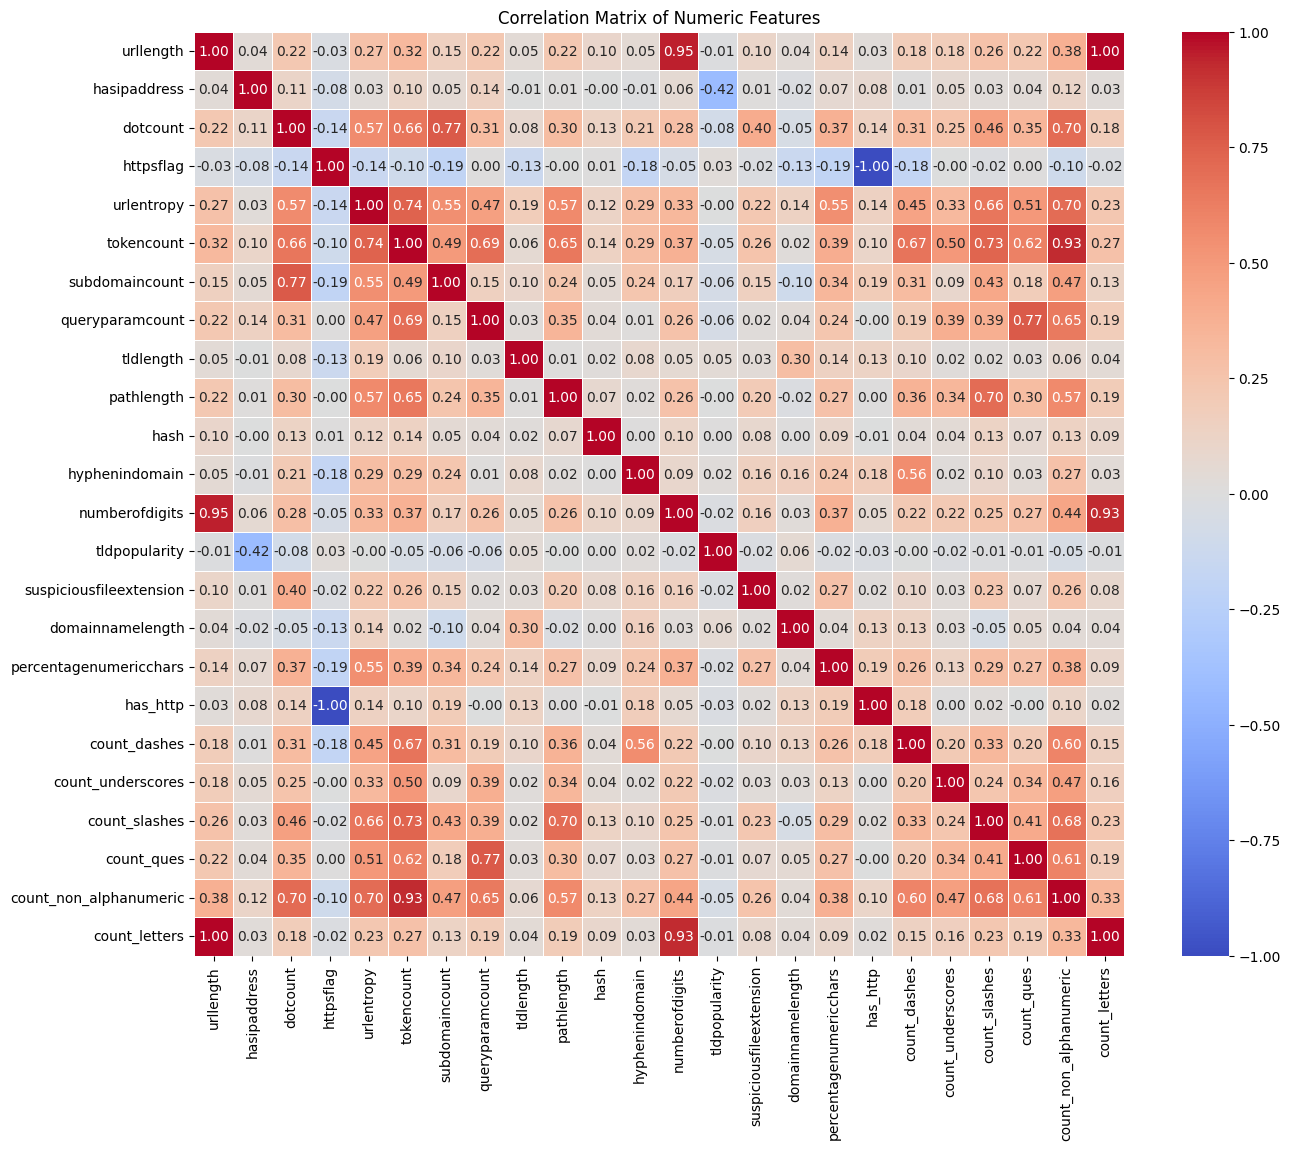


Highly Correlated Feature Pairs (> 0.8 or < -0.8):
  - numberofdigits and urllength: Correlation = 0.95
  - has_http and httpsflag: Correlation = -1.00
  - count_non_alphanumeric and tokencount: Correlation = 0.93
  - count_letters and urllength: Correlation = 1.00
  - count_letters and numberofdigits: Correlation = 0.93


In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

print("=" * 30)
print("Checking for Multicollinearity (Correlation Matrix)")
print("=" * 30)

# Compute correlation matrix for numeric features
df_numeric_features = df_features.select_dtypes(include=np.number).drop(columns=['ClassLabel'], errors='ignore')
correlation_matrix = df_numeric_features.corr()

# Visualize the correlation matrix
plt.figure(figsize=(15, 12))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Numeric Features')
plt.show()

# Identify highly correlated feature pairs
# Get the upper triangle of the correlation matrix to avoid duplicates
uppertri_corr = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))

# Find features with high correlation (e.g., > 0.8 or < -0.8)
highly_correlated_pairs = []
for col in uppertri_corr.columns:
    high_corr_cols = uppertri_corr[col][(uppertri_corr[col].abs() > 0.8)].index.tolist()
    for hc_col in high_corr_cols:
        highly_correlated_pairs.append((col, hc_col, uppertri_corr[col][hc_col]))

if highly_correlated_pairs:
    print("\nHighly Correlated Feature Pairs (> 0.8 or < -0.8):")
    for f1, f2, corr_val in highly_correlated_pairs:
        print(f"  - {f1} and {f2}: Correlation = {corr_val:.2f}")
else:
    print("No highly correlated feature pairs (> 0.8 or < -0.8) found.")

### E. Handling Multicollinearity: Feature Removal

In [7]:
# Create a copy of the DataFrame to avoid modifying the original directly
df_features_processed = df_features.copy()

# List of features to be removed based on multicollinearity analysis
# Choosing one from each highly correlated pair
features_to_drop_multicollinearity = [
    'has_http',         # Perfectly correlated with httpsflag
    'tokencount',        # Highly correlated with count_non_alphanumeric
    'count_letters',
    'numberofdigits'
]

print("=" * 30)
print("Multicollinearity Handling")
print("=" * 30)

print(f"Features to be removed due to multicollinearity: {features_to_drop_multicollinearity}")

df_features_processed = df_features_processed.drop(columns=features_to_drop_multicollinearity)

print(f"\nNumber of columns after removal: {df_features_processed.shape[1]}")
print("Remaining columns list:")
print(df_features_processed.columns.tolist())

# Export the 20 features dataset (plus URL and ClassLabel) to a separate file
output_features_20 = 'dataset_features_20.csv'
df_features_processed.to_csv(output_features_20, index=False)
print(f"\nDataset with 20 features successfully saved to: {output_features_20}")

# Trigger automatic download in Google Colab
try:
    from google.colab import files
    print(f"Starting automatic download: {output_features_20}...")
    files.download(output_features_20)
except ImportError:
    import os
    full_path = os.path.abspath(output_features_20)
    print(f"\nRunning locally. File saved at:\n{full_path}")

Multicollinearity Handling
Features to be removed due to multicollinearity: ['has_http', 'tokencount', 'count_letters', 'numberofdigits']

Number of columns after removal: 22
Remaining columns list:
['URL', 'ClassLabel', 'urllength', 'hasipaddress', 'dotcount', 'httpsflag', 'urlentropy', 'subdomaincount', 'queryparamcount', 'tldlength', 'pathlength', 'hash', 'hyphenindomain', 'tldpopularity', 'suspiciousfileextension', 'domainnamelength', 'percentagenumericchars', 'count_dashes', 'count_underscores', 'count_slashes', 'count_ques', 'count_non_alphanumeric']

Dataset with 20 features successfully saved to: dataset_features_20.csv
Starting automatic download: dataset_features_20.csv...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Checking Multicollinearity After Feature Removal


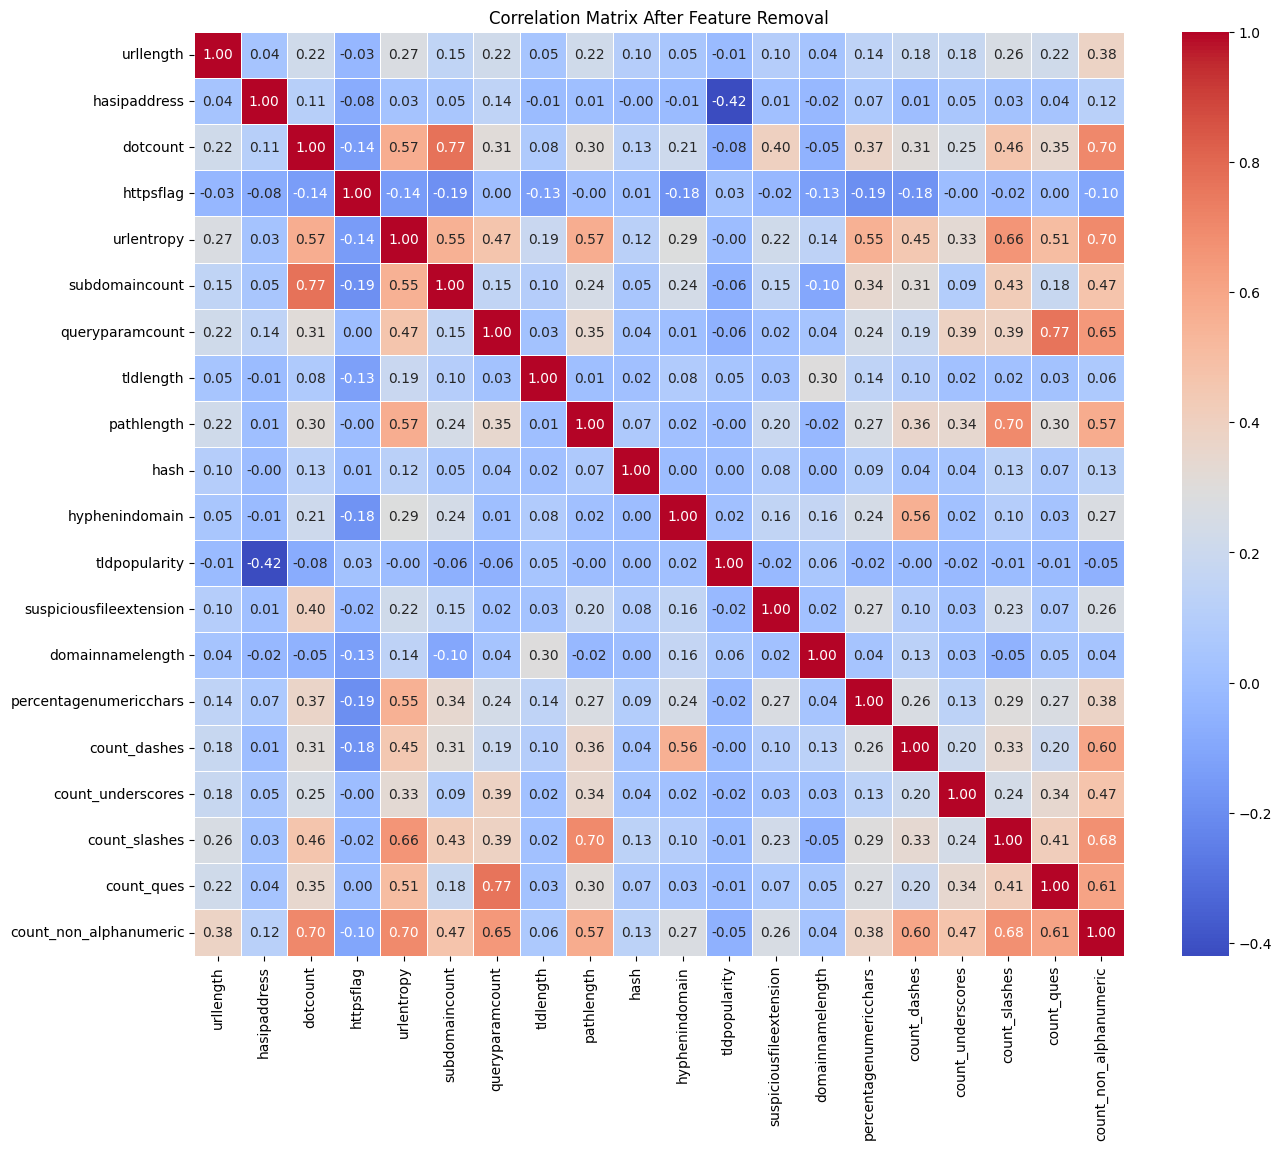

No highly correlated feature pairs (> 0.8 or < -0.8) remaining after removal.


In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

print("=" * 30)
print("Checking Multicollinearity After Feature Removal")
print("=" * 30)

# Ensure df_features_processed is already defined from previous steps
if 'df_features_processed' not in locals():
    print("Error: df_features_processed not found. Please run the previous cell.")
else:
    # Compute correlation matrix for remaining numeric features
    df_numeric_features_processed = df_features_processed.select_dtypes(include=np.number).drop(columns=['ClassLabel'], errors='ignore')
    correlation_matrix_processed = df_numeric_features_processed.corr()

    # Visualize the updated correlation matrix
    plt.figure(figsize=(15, 12))
    sns.heatmap(correlation_matrix_processed, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
    plt.title('Correlation Matrix After Feature Removal')
    plt.show()

    # Identify highly correlated features after removal
    uppertri_corr_processed = correlation_matrix_processed.where(np.triu(np.ones(correlation_matrix_processed.shape), k=1).astype(bool))

    highly_correlated_pairs_processed = []
    for col in uppertri_corr_processed.columns:
        # High correlation threshold (> 0.8 or < -0.8)
        high_corr_cols_processed = uppertri_corr_processed[col][(uppertri_corr_processed[col].abs() > 0.8)].index.tolist()
        for hc_col in high_corr_cols_processed:
            highly_correlated_pairs_processed.append((col, hc_col, uppertri_corr_processed[col][hc_col]))

    if highly_correlated_pairs_processed:
        print("\nHighly Correlated Feature Pairs (> 0.8 or < -0.8) After Removal:")
        for f1, f2, corr_val in highly_correlated_pairs_processed:
            print(f"  - {f1} and {f2}: Correlation = {corr_val:.2f}")
        print("\nSome highly correlated features still persist. Consider further removals if necessary.")
    else:
        print("No highly correlated feature pairs (> 0.8 or < -0.8) remaining after removal.")